# BERT for Spam vs. Ham Email Classification


> **Runtime note:** Fine-tuning downloads a pretrained model and needs internet access for the first run. A GPU is recommended, but a CPU can work slowly. This notebook uses the Hugging Face PyTorch workflow because it is widely supported for BERT fine-tuning.

## What is BERT?

**BERT** stands for **Bidirectional Encoder Representations from Transformers**. It is a pretrained language model introduced by Google. BERT uses the **Transformer encoder** architecture to create contextual representations of text.

### What does “bidirectional” mean?
When representing a word, BERT can use context from both the left and right sides of the word. For example, the meaning of *bank* differs in “river bank” and “bank account”; context helps BERT represent the word appropriately.

### BERT components
1. **WordPiece tokenizer:** splits text into tokens/subword pieces.
2. **Token embeddings:** represent token identities.
3. **Position embeddings:** represent token positions.
4. **Segment/token-type embeddings:** can distinguish paired text segments.
5. **Transformer encoder layers:** use multi-head self-attention and feed-forward networks.
6. **[CLS] representation:** a special token commonly used as a sequence-level representation for classification.
7. **Classification head:** maps the representation to class logits, here `ham` or `spam`.

### Pretraining vs. fine-tuning
- **Pretraining:** BERT learns general language patterns from large text corpora.
- **Fine-tuning:** we continue training BERT on labeled email examples for our specific task.

BERT is an encoder model designed for understanding tasks. Unlike a typical decoder-only language model, it is not primarily designed to generate text token by token.

If required, run the installation cell below. Then restart the kernel if the environment asks you to.

In [2]:
%pip install -q transformers datasets accelerate scikit-learn pandas matplotlib seaborn

Note: you may need to restart the kernel to use updated packages.


  You can safely remove it manually.


In [1]:
import os
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix
)

print("PyTorch:", torch.__version__)
print("CUDA/GPU available:", torch.cuda.is_available())

PyTorch: 2.14.1+cpu
CUDA/GPU available: False


## Load the provided dataset

Place `spam.csv` in the same folder as this notebook. 
The dataset contains:
- `type`: label (`ham` or `spam`)
- `email`: email/message text

The CSV is read with `latin1` encoding because the file contains characters that are not valid UTF-8.

In [2]:
candidate_paths = [
    "spam.csv",
    "spam(2).csv",
    "/mnt/data/spam(1).csv",
    "/mnt/data/spam.csv"
]
csv_path = next((p for p in candidate_paths if os.path.exists(p)), None)
if csv_path is None:
    raise FileNotFoundError(
        "Could not find the dataset. Put spam.csv or spam(1).csv beside this notebook."
    )

df = pd.read_csv(csv_path, encoding="latin1")
print("Loaded:", csv_path)
print("Dataset shape:", df.shape)
display(df.head())
print("Columns:", df.columns.tolist())

Loaded: spam(2).csv
Dataset shape: (5572, 2)


,type,email
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."


Columns: ['type', 'email']


## Clean and explore the data

We standardize labels, remove missing rows, and remove exact duplicate examples. We do not aggressively remove punctuation or stopwords: BERT's tokenizer is designed to process natural text, and punctuation can carry useful meaning.

In [3]:
df = df[["type", "email"]].copy()
df = df.dropna(subset=["type", "email"])
df["type"] = df["type"].astype(str).str.strip().str.lower()
df["email"] = df["email"].astype(str).str.strip()
df = df[df["type"].isin(["ham", "spam"])]
df = df[df["email"].str.len() > 0]
df = df.drop_duplicates(subset=["type", "email"]).reset_index(drop=True)

label_to_id = {"ham": 0, "spam": 1}
id_to_label = {0: "ham", 1: "spam"}
df["label"] = df["type"].map(label_to_id).astype(int)

print("Cleaned shape:", df.shape)
display(df.head())

Cleaned shape: (5158, 3)


,type,email,label
0,ham,"Go until jurong point, crazy.. Available only ...",0
1,ham,Ok lar... Joking wif u oni...,0
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...,1
3,ham,U dun say so early hor... U c already then say...,0
4,ham,"Nah I don't think he goes to usf, he lives aro...",0


Class counts:


,count
class,
ham,4516
spam,642


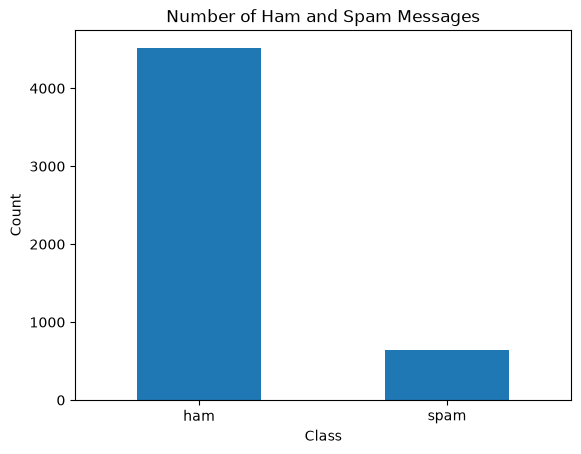

,count,mean,std,min,25%,50%,75%,max
type,,,,,,,,
ham,4516.0,70.4,56.4,2.0,34.0,52.0,90.0,910.0
spam,642.0,137.6,30.3,13.0,131.2,148.0,157.0,224.0


In [4]:
print("Class counts:")
display(df["type"].value_counts().rename_axis("class").to_frame("count"))

df["type"].value_counts().plot(kind="bar", title="Number of Ham and Spam Messages")
plt.xlabel("Class")
plt.ylabel("Count")
plt.xticks(rotation=0)
plt.show()

df["text_length"] = df["email"].str.len()
display(df.groupby("type")["text_length"].describe().round(1))

### Class imbalance

Spam/ham datasets often contain more ham than spam. Therefore, accuracy alone can be misleading. We will also examine precision, recall, F1-score, and the confusion matrix. A stratified split keeps approximately the same class proportions in train and test sets.

## Create train and test sets

The test set is held back until final evaluation. We also use a validation set to monitor training.

In [5]:
train_df, test_df = train_test_split(
    df[["email", "label"]],
    test_size=0.15,
    random_state=42,
    stratify=df["label"]
)
train_df, val_df = train_test_split(
    train_df,
    test_size=0.15,
    random_state=42,
    stratify=train_df["label"]
)

print("Train:", train_df.shape, "Validation:", val_df.shape, "Test:", test_df.shape)
print("Train label proportions:")
display(train_df["label"].value_counts(normalize=True).sort_index())

Train: (3726, 2) Validation: (658, 2) Test: (774, 2)
Train label proportions:


label
0    0.87547
1    0.12453
Name: proportion, dtype: float64

## Load BERT tokenizer

We use `bert-base-uncased`, which lowercases text. The tokenizer converts each email into token IDs, adds special tokens such as `[CLS]` and `[SEP]`, and creates an attention mask.

- `input_ids`: numerical token IDs
- `attention_mask`: `1` for real tokens and `0` for padding
- `max_length`: maximum sequence length; longer messages are truncated

We use 128 tokens as a practical starting point. Increase it if longer emails are important, while considering memory and speed.

In [6]:
from transformers import AutoTokenizer, AutoModelForSequenceClassification

MODEL_NAME = "bert-base-uncased"
MAX_LENGTH = 128

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

example_text = train_df.iloc[0]["email"]
example_tokens = tokenizer(
    example_text,
    truncation=True,
    padding="max_length",
    max_length=MAX_LENGTH
)
print("Email:", example_text)
print("Tokens:", tokenizer.convert_ids_to_tokens(example_tokens["input_ids"][:25]))
print("Token IDs (first 25):", example_tokens["input_ids"][:25])
print("Attention mask (first 25):", example_tokens["attention_mask"][:25])

Email: For me the love should start with attraction.i should feel that I need her every time around me.she should be the first thing which comes in my thoughts.I would start the day and end it with her.she should be there every time I dream.love will be then when my every breath has her name.my life should happen around her.my life will be named to her.I would cry for her.will give all my happiness and take all her sorrows.I will be ready to fight with anyone for her.I will be in love when I will be doing the craziest things for her.love will be when I don't have to proove anyone that my girl is the most beautiful lady on the whole planet.I will always be singing praises for her.love will be when I start up making chicken curry and end up makiing sambar.life will be the most beautiful then.will get every morning and thank god for the day because she is with me.I would like to say a lot..will tell later..
Tokens: ['[CLS]', 'for', 'me', 'the', 'love', 'should', 'start', 'with', 'attracti

## Prepare a PyTorch Dataset

Each example returns token IDs, attention mask, and its numeric class label. The Hugging Face model accepts these tensors directly.

In [7]:
from torch.utils.data import Dataset

class EmailDataset(Dataset):
    def __init__(self, frame, tokenizer, max_length=128):
        self.texts = frame["email"].astype(str).tolist()
        self.labels = frame["label"].astype(int).tolist()
        self.tokenizer = tokenizer
        self.max_length = max_length

    def __len__(self):
        return len(self.texts)

    def __getitem__(self, idx):
        encoded = self.tokenizer(
            self.texts[idx],
            truncation=True,
            padding="max_length",
            max_length=self.max_length,
            return_tensors="pt"
        )
        item = {key: value.squeeze(0) for key, value in encoded.items()}
        item["labels"] = torch.tensor(self.labels[idx], dtype=torch.long)
        return item

train_dataset = EmailDataset(train_df, tokenizer, MAX_LENGTH)
val_dataset = EmailDataset(val_df, tokenizer, MAX_LENGTH)
test_dataset = EmailDataset(test_df, tokenizer, MAX_LENGTH)

sample = train_dataset[0]
{key: tuple(value.shape) for key, value in sample.items()}

{'input_ids': (128,),
 'token_type_ids': (128,),
 'attention_mask': (128,),
 'labels': ()}

## Load pretrained BERT for classification

`AutoModelForSequenceClassification` loads pretrained BERT and adds a classification head with two outputs. Fine-tuning updates the model weights on our labeled examples.

This is **transfer learning**: we reuse language knowledge learned during pretraining and adapt it to email classification.

In [8]:
from transformers import Trainer, TrainingArguments, DataCollatorWithPadding

model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME,
    num_labels=2,
    id2label=id_to_label,
    label2id=label_to_id
)

print("Device:", "cuda" if torch.cuda.is_available() else "cpu")
print("Trainable parameters:", sum(p.numel() for p in model.parameters() if p.requires_grad))

C:\Users\Datamites\anaconda3\Lib\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\Datamites\.cache\huggingface\hub. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)


model.safetensors: reconstructing file:   0%|          |  0.00B /  440MB            

model.safetensors: downloading bytes:           |  0.00B            

C:\Users\Datamites\anaconda3\Lib\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\Datamites\.cache\huggingface\hub\models--bert-base-uncased. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Device: cpu
Trainable parameters: 109483778


## Configure and fine-tune BERT

The settings below are intentionally modest. Fine-tuning can take several minutes or longer, especially on CPU.

- `learning_rate=2e-5`: common starting scale for BERT fine-tuning
- `num_train_epochs=2`: short demonstration run
- `load_best_model_at_end=True`: restores the checkpoint with the best validation F1
- `fp16`: enabled only when CUDA is available

If your installed Transformers version reports an argument compatibility error, update the package and restart the kernel.

In [9]:
def compute_metrics(eval_pred):
    logits, labels = eval_pred
    predictions = np.argmax(logits, axis=-1)
    return {
        "accuracy": accuracy_score(labels, predictions),
        "precision_spam": precision_score(labels, predictions, pos_label=1, zero_division=0),
        "recall_spam": recall_score(labels, predictions, pos_label=1, zero_division=0),
        "f1_spam": f1_score(labels, predictions, pos_label=1, zero_division=0)
    }

training_args = TrainingArguments(
    output_dir="./bert_spam_results",
    eval_strategy="epoch",
    save_strategy="epoch",
    learning_rate=2e-5,
    per_device_train_batch_size=8,
    per_device_eval_batch_size=16,
    num_train_epochs=2,
    weight_decay=0.01,
    load_best_model_at_end=True,
    metric_for_best_model="f1_spam",
    greater_is_better=True,
    logging_steps=50,
    report_to="none",
    fp16=torch.cuda.is_available(),
    save_total_limit=2,
    seed=42
)

trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=train_dataset,
    eval_dataset=val_dataset,
    compute_metrics=compute_metrics,
    data_collator=DataCollatorWithPadding(tokenizer=tokenizer)
)

print("Trainer is ready.")

Trainer is ready.


In [ ]:
# Fine-tune BERT. This step downloads model weights if not already cached.
train_result = trainer.train()
print(train_result)

C:\Users\Datamites\anaconda3\Lib\site-packages\torch\utils\data\dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


Epoch,Training Loss,Validation Loss


## Evaluate on the held-out test set

The test set was not used to update model weights. We report several metrics:

- **Precision (spam):** among emails predicted as spam, how many really were spam?
- **Recall (spam):** among all real spam emails, how many did the model detect?
- **F1-score:** harmonic mean of precision and recall.
- **Confusion matrix:** counts of correct and incorrect predictions.

In [ ]:
test_output = trainer.predict(test_dataset)
test_logits = test_output.predictions
y_true = test_df["label"].to_numpy()
y_pred = np.argmax(test_logits, axis=1)

print(classification_report(
    y_true, y_pred,
    labels=[0, 1],
    target_names=["ham", "spam"],
    digits=4,
    zero_division=0
))

cm = confusion_matrix(y_true, y_pred, labels=[0, 1])
sns.heatmap(
    cm, annot=True, fmt="d", cmap="Blues",
    xticklabels=["Predicted ham", "Predicted spam"],
    yticklabels=["Actual ham", "Actual spam"]
)
plt.title("BERT Spam/Ham Confusion Matrix")
plt.ylabel("Actual label")
plt.xlabel("Predicted label")
plt.show()

## Predict a new email

The function below returns the predicted class and class probabilities. Use the probabilities as model estimates, not as certainty. The decision threshold can be adjusted based on the relative cost of missing spam versus incorrectly flagging legitimate email.

In [ ]:
def predict_email(text):
    model.eval()
    inputs = tokenizer(
        text,
        return_tensors="pt",
        truncation=True,
        padding=True,
        max_length=MAX_LENGTH
    )
    device = next(model.parameters()).device
    inputs = {key: value.to(device) for key, value in inputs.items()}

    with torch.no_grad():
        logits = model(**inputs).logits
        probabilities = torch.softmax(logits, dim=1)[0].cpu().numpy()

    predicted_id = int(np.argmax(probabilities))
    return {
        "email": text,
        "prediction": id_to_label[predicted_id],
        "ham_probability": round(float(probabilities[0]), 4),
        "spam_probability": round(float(probabilities[1]), 4)
    }

examples = [
    "Congratulations! You have won a free prize. Click here to claim now.",
    "Hi, can we reschedule our meeting for tomorrow afternoon?",
    "URGENT! Claim your cash reward now by texting WIN."
]
for email in examples:
    print(predict_email(email), "\n")

## Save the fine-tuned model

The model and tokenizer can be saved and reloaded later without retraining.

In [11]:
save_dir = "./bert_spam_ham_model"
trainer.save_model(save_dir)
tokenizer.save_pretrained(save_dir)
print("Saved model and tokenizer to:", save_dir)

NameError: name 'trainer' is not defined